# Day 3 lecture: Text mining

<p class="lead">
Most of what customers tell a business arrives as text: reviews, complaints, chat messages and survey comments. This lecture turns unstructured text into numbers a manager can act on: split it into words, remove the noise, count what people talk about, draw it, score how they feel with the VADER sentiment model, check that score against a second source, and finish with a recommendation.
</p>

Open this notebook in JupyterLab from the course folder and run each cell from top to bottom with **Shift + Enter**.

---

## What you will be able to do

1. Explain the difference between **structured** and **unstructured** data, and name business sources of text.
2. **Tokenise** text into words and explain why case, punctuation and numbers need a decision.
3. Remove **stopwords**, add your own domain stopwords, and explain why stopwords must stay in for sentiment.
4. Count **word frequencies**, draw them as a bar chart and as a **word cloud**, and say what each is good for.
5. Score text with **VADER**: read the compound score, apply the ±0.05 thresholds and explain the rules VADER uses.
6. Check sentiment scores against a second source and name VADER's main blind spots.
7. Turn review text into a **decision**: which problem to fix first, with evidence and caveats.

**Reading:** Label Your Data (n.d.), *Unstructured text in data mining: Unlocking valuable insights*.

> **How to use the questions in this notebook**
>
> **Predict, then reveal** boxes ask you to guess before running the next cell. Write your guess down first. **Check your understanding** boxes are short questions to answer in your own words, alone or with the person next to you.

| Part | Topic |
|---|---|
| 1 | Unstructured text and the text-mining routine |
| 2 | Tokenising |
| 3 | Stopwords |
| 4 | Word frequency |
| 5 | Word clouds and word pairs |
| 6 | Sentiment with VADER |
| 7 | Checking the scores against star ratings |
| 8 | From reviews to a decision |

---

## Recap: Day 2

Answer in your own words before we start.

1. Which chart do you choose to **compare** categories, and why does it beat a pie chart?
2. What is a **message title**? Rewrite "Reviews by star rating" as one.
3. Why should a KPI such as "share of unhappy customers" be computed as a **ratio of sums** across branches?

---

## Part 1: Unstructured text and the text-mining routine

**Structured data** fits a table with fixed columns: an order has a date, a product, a price. **Unstructured data** has no fixed columns: a review is a free sentence that may mention the price, the staff and the weather at once. Analysts estimate that most of the data organisations hold is unstructured, and most of it is text.

| Source of text | Typical question |
|---|---|
| Product and app reviews | What do customers praise and complain about? |
| Customer-service chats and emails | Which problems cause most contacts? |
| Survey comments ("anything else?") | Why did the satisfaction score drop? |
| Social media posts | How do people react to a launch or a crisis? |
| Contracts, reports, job adverts | Which clauses, risks or skills appear most often? |

**Text mining** is the set of methods that turn text into structured numbers (counts, scores, categories) that can be summarised, charted and joined to the rest of the business data. Every project follows the same routine:

| Step | What happens | In this lecture |
|---|---|---|
| 1. Collect | Gather the texts and their context (date, branch, rating) | 30 reviews with a branch and a star rating |
| 2. Clean | Lowercase, decide what to do with punctuation and numbers | Part 2 |
| 3. Tokenise | Split each text into words (**tokens**) | Part 2 |
| 4. Filter | Remove words that carry no signal (**stopwords**) | Part 3 |
| 5. Represent | Turn tokens into numbers: counts, pairs, scores | Parts 4–6 |
| 6. Analyse and check | Summarise, chart, compare with another source | Parts 4–7 |
| 7. Decide | Recommend an action, with evidence and limits | Part 8 |

### The case: LeafLine Tea

**LeafLine Tea** is a made-up bubble-tea chain with three branches: near a university campus, near a railway station and on a riverside shopping street. Head office has 30 recent customer reviews, each with a star rating from 1 (worst) to 5 (best). The operations manager asks: **what should we fix first?**

The reviews are **synthetic**: written for teaching, not collected from real customers.

Run the two setup cells. The first one tells NLTK, the Natural Language Toolkit, to use the word lists bundled in the `data` folder, so nothing is downloaded. The second loads the other libraries and the reviews.

In [1]:
import zipfile
from pathlib import Path

import nltk

NLTK_DIR = Path("data/nltk_data").resolve()
if not (NLTK_DIR / "tokenizers" / "punkt_tab").exists():
    with zipfile.ZipFile(NLTK_DIR / "tokenizers" / "punkt_tab.zip") as z:
        z.extractall(NLTK_DIR / "tokenizers")
nltk.data.path.insert(0, str(NLTK_DIR))

In [2]:
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from nltk.corpus import stopwords
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from nltk.tokenize import word_tokenize
from wordcloud import WordCloud

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GREY = "#c9c7c1"   # context
INK = "#55534e"    # notes and labels
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
pd.set_option("display.max_colwidth", 90)

# SYNTHETIC reviews written for teaching: (branch, stars 1-5, review text)
REVIEWS = [
    ("Riverside", 5, "The brown sugar milk tea is delicious and the pearls are perfectly chewy. My new favourite shop!"),
    ("Riverside", 2, "Waited 35 minutes for one drink. The queue was huge and nobody explained the delay."),
    ("Riverside", 4, "Tasty mango tea and friendly staff, but the wait was a bit long at lunchtime."),
    ("Riverside", 1, "The app crashed twice while I was paying, and my order was lost. Very frustrating."),
    ("Riverside", 5, "Great taste, fair price, quick service. Highly recommend the jasmine green tea."),
    ("Riverside", 3, "The drink was okay. Not bad, not special."),
    ("Riverside", 2, "Too sweet even at 30% sugar, and the ice melted before I got back to the office."),
    ("Riverside", 1, "Great, another 40 minute wait for a lukewarm drink."),
    ("Riverside", 4, "Love the new oat milk option. A little expensive, but worth it."),
    ("Riverside", 2, "The app showed my order as ready but the staff could not find it. I waited another 20 minutes."),
    ("Campus", 5, "Cheap, fast and delicious. Perfect between classes!"),
    ("Campus", 4, "Good tea and friendly staff. The queue moves fast."),
    ("Campus", 3, "Price is fine. The taste is average."),
    ("Campus", 5, "Best taro milk tea in the city. The staff are always kind."),
    ("Campus", 2, "The app would not accept my student discount code, so I paid full price."),
    ("Campus", 4, "Nice cheese foam, quick pickup with the app. Seats are limited."),
    ("Campus", 1, "Found a hair in my drink. Disgusting. I complained and nobody cared."),
    ("Campus", 5, "The app is easy to use and my drink was ready before I reached the counter. Excellent."),
    ("Campus", 3, "Not the worst tea I have had, but the pearls were hard."),
    ("Campus", 4, "Delicious peach oolong. The music is too loud, though."),
    ("Station", 2, "Slow service. I missed my train because the order took 25 minutes."),
    ("Station", 1, "Terrible. Cold drink, rude cashier and a long wait."),
    ("Station", 2, "Convenient location, but the wait times are unpredictable."),
    ("Station", 4, "Good drinks and the app lets me order before I arrive. The wait is shorter that way."),
    ("Station", 2, "The app kept logging me out, and the queue was very long."),
    ("Station", 5, "Friendly staff and the best brown sugar tea. Worth the wait!"),
    ("Station", 1, "Overpriced and watery. Never again."),
    ("Station", 3, "The drink was fine but the app charged me twice. Refund took a week."),
    ("Station", 4, "Tasty and fresh. The staff were busy but polite."),
    ("Station", 2, "Waited 30 minutes at the counter while app orders kept jumping the queue."),
]
reviews = pd.DataFrame(REVIEWS, columns=["branch", "stars", "text"])
reviews.index = pd.RangeIndex(1, len(reviews) + 1, name="review_id")

print("Reviews:", len(reviews))
print(reviews["branch"].value_counts().sort_index().to_string())
reviews.head()

Reviews: 30
branch
Campus       10
Riverside    10
Station      10


,branch,stars,text
review_id,,,
1,Riverside,5,The brown sugar milk tea is delicious and the pearls are perfectly chewy. My new favou...
2,Riverside,2,Waited 35 minutes for one drink. The queue was huge and nobody explained the delay.
3,Riverside,4,"Tasty mango tea and friendly staff, but the wait was a bit long at lunchtime."
4,Riverside,1,"The app crashed twice while I was paying, and my order was lost. Very frustrating."
5,Riverside,5,"Great taste, fair price, quick service. Highly recommend the jasmine green tea."


One row is **one review**: one customer's comment about one visit. The `stars` column is structured; the `text` column is unstructured. The rest of the lecture turns the text into columns we can count.

---

## Part 2: Tokenising

A computer sees a review as one long string of characters. **Tokenising** splits it into units, usually words, called **tokens**. Before that we make a few cleaning decisions:

| Decision | Usual choice | Why |
|---|---|---|
| Upper and lower case | Lowercase everything | "Great" and "great" should count as one word |
| Punctuation | Drop it for counting, keep it for sentiment | "!" carries feeling but is not a topic |
| Numbers | Drop for word counts | "35" is not a topic; "35 minutes" is, as a phrase |
| Contractions ("I've", "don't") | Let the tokenizer split them | `word_tokenize` gives "I" + "'ve" and "do" + "n't" |

> **Predict, then reveal**
>
> The next cell splits review 6, *"The drink was okay. Not bad, not special."*, in two ways: Python's simple `split()` on spaces, and NLTK's `word_tokenize`. How many tokens will each give, and what will be different about the commas and full stops?

In [3]:
example = reviews.loc[6, "text"]

by_spaces = example.split()
by_nltk = word_tokenize(example.lower())

print("split() on spaces:", len(by_spaces), "tokens")
print(by_spaces)
print()
print("word_tokenize on lowercase text:", len(by_nltk), "tokens")
print(by_nltk)

split() on spaces: 8 tokens
['The', 'drink', 'was', 'okay.', 'Not', 'bad,', 'not', 'special.']

word_tokenize on lowercase text: 11 tokens
['the', 'drink', 'was', 'okay', '.', 'not', 'bad', ',', 'not', 'special', '.']


`split()` leaves punctuation glued to words, so `okay.` and `okay` would be counted as different words. `word_tokenize` separates punctuation into tokens of its own, which we can then drop with one test: keep a token only if `token.isalpha()` is true (it contains letters only).

Now tokenise all 30 reviews at once and keep the alphabetic tokens:

In [4]:
reviews["tokens"] = reviews["text"].str.lower().apply(word_tokenize)
reviews["words"] = reviews["tokens"].apply(lambda tokens: [t for t in tokens if t.isalpha()])

all_words = [w for words in reviews["words"] for w in words]
print("Alphabetic tokens in all reviews:", len(all_words))
print("Different words (the vocabulary):", len(set(all_words)))
print()
print("Ten most common words so far:")
print(Counter(all_words).most_common(10))

Alphabetic tokens in all reviews: 353
Different words (the vocabulary): 172

Ten most common words so far:
[('the', 37), ('and', 15), ('app', 9), ('i', 9), ('was', 8), ('tea', 7), ('my', 7), ('drink', 7), ('but', 7), ('is', 6)]


> **Predict, then reveal**
>
> Look at the ten most common words above. Do they tell the operations manager anything about what to fix? What kind of words are they?

---

## Part 3: Stopwords

Most of the top words above are **stopwords**: very common words such as *the*, *and*, *is*, *a* that hold sentences together but say nothing about the topic. NLTK ships a list of English stopwords:

In [5]:
english_stopwords = set(stopwords.words("english"))
print("Stopwords in NLTK's English list:", len(english_stopwords))
print("A few of them:", sorted(english_stopwords)[:25])
print()
for word in ["not", "no", "very", "but", "too"]:
    print(f"Is '{word}' a stopword? {word in english_stopwords}")

Stopwords in NLTK's English list: 198
A few of them: ['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both']

Is 'not' a stopword? True
Is 'no' a stopword? True
Is 'very' a stopword? True
Is 'but' a stopword? True
Is 'too' a stopword? True


Two things to notice in the output above:

1. The standard list is a starting point. In our reviews, words like *tea* and *drink* appear everywhere because every review is about tea. They are **domain stopwords**: frequent, but they cannot separate one complaint from another. We add them ourselves.
2. *not*, *no*, *very*, *but* and *too* are all in the list. For counting **topics** that is fine. For **sentiment** it is a disaster: "not good" becomes "good". So we remove stopwords only for word counts, and we always run sentiment on the original text.

In [6]:
DOMAIN_STOPWORDS = {"tea", "drink", "drinks", "milk"}
stop = english_stopwords | DOMAIN_STOPWORDS

reviews["content_words"] = reviews["words"].apply(lambda words: [w for w in words if w not in stop])
content_words = [w for words in reviews["content_words"] for w in words]

print("Words before removing stopwords:", len(all_words))
print("Words after:", len(content_words))
print(f"Share of words removed: {1 - len(content_words) / len(all_words):.0%}")

Words before removing stopwords: 353
Words after: 196
Share of words removed: 44%


> **Check your understanding**
>
> 1. A hotel analyses 5,000 guest reviews. Name two words you would add as domain stopwords, and one frequent word you would **keep** even though it is common.
> 2. Why must "not" stay in the text when you score sentiment?

---

## Part 4: Word frequency

With the noise removed, a **frequency distribution** counts how often each remaining word appears. NLTK's `FreqDist` is a counter with a `most_common` method.

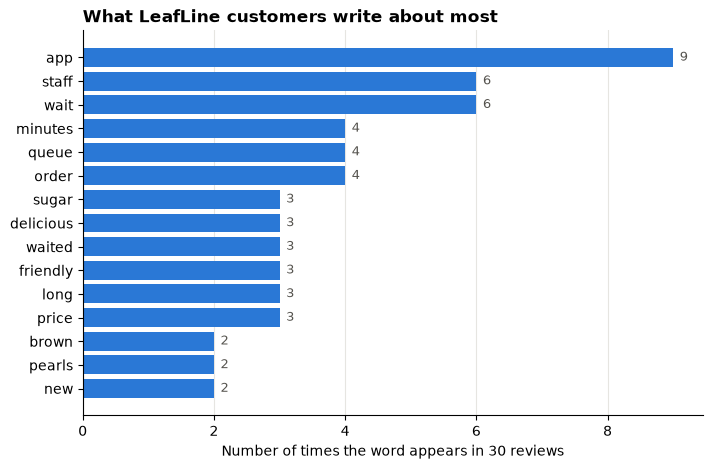

In [7]:
freq = nltk.FreqDist(content_words)
top = pd.Series(dict(freq.most_common(15)), name="count")

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index[::-1], top.values[::-1], color=BLUE)
for i, value in enumerate(top.values[::-1]):
    ax.text(value + 0.1, i, str(value), va="center", fontsize=9, color=INK)
ax.set_title("What LeafLine customers write about most")
ax.set_xlabel("Number of times the word appears in 30 reviews")
ax.grid(axis="x", color="#e6e5e1")
ax.set_axisbelow(True)
plt.show()

Read the bar chart above as the manager would: which words about the **service** appear near the top, and which about the **product**? Notice that *wait* and *waited* are counted as two different words. Grouping word forms is called **stemming** or **lemmatising**; in a short analysis, a hand-made keyword list (Part 8) does the same job more transparently.

> **Word counts are not opinions**
>
> A frequent word tells you what people talk about, not whether they like it. *app* can appear in praise ("easy to use") and in complaints ("crashed"). Frequency says **where to look**; sentiment and reading the reviews say **what is wrong**.

---

## Part 5: Word clouds and word pairs

A **word cloud** draws each word with a size proportional to its frequency. We build it from the same counts, with a fixed `random_state` so the layout is the same each time you run it.

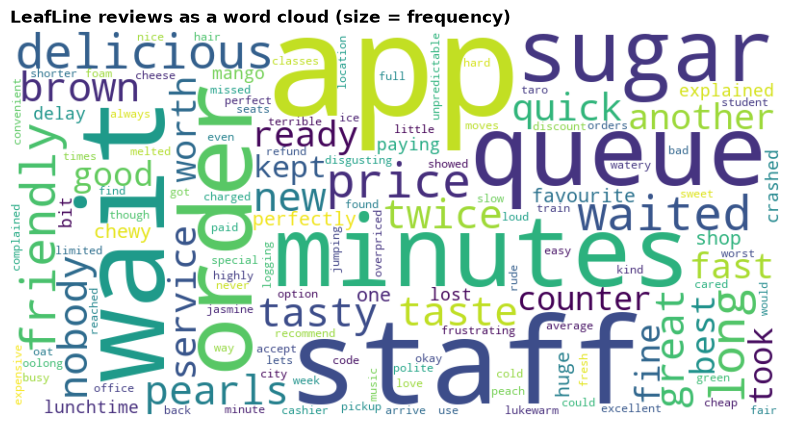

In [8]:
cloud = WordCloud(
    width=800, height=400, background_color="white", colormap="viridis", random_state=3
).generate_from_frequencies(freq)

plt.figure(figsize=(10, 5))
plt.imshow(cloud, interpolation="bilinear")
plt.axis("off")
plt.title("LeafLine reviews as a word cloud (size = frequency)")
plt.show()

Compare the cloud with the bar chart in Part 4, using what you learned on Day 2 about encodings:

| | Word cloud | Sorted bar chart |
|---|---|---|
| Encoding | Area and font size (read poorly) | Length from a common baseline (read well) |
| Ranking | Hard beyond the top two or three words | The reading order |
| Exact counts | Not shown | Labelled |
| Long words | Look more important than they are | No bias |
| Best use | A first impression, a slide that invites discussion | Any comparison you will base a decision on |

### Word pairs (bigrams)

Single words lose context: *brown* and *sugar* mean more together. A **bigram** is a pair of neighbouring words. We count pairs within each review, so the last word of one review never pairs with the first word of the next.

In [9]:
pairs = Counter()
for words in reviews["content_words"]:
    pairs.update(nltk.bigrams(words))

print("Most common word pairs (after removing stopwords):")
for (first, second), count in pairs.most_common(8):
    print(f"  {first} {second}: {count}")

Most common word pairs (after removing stopwords):
  friendly staff: 3
  brown sugar: 2
  waited minutes: 2
  sugar delicious: 1
  delicious pearls: 1
  pearls perfectly: 1
  perfectly chewy: 1
  chewy new: 1


Pairs such as a product name ("brown sugar") or a complaint ("long wait") are often more useful than single words. With thousands of reviews, pairs and triples become the main source of key phrases.

> **Check your understanding**
>
> Your manager wants a word cloud of 10,000 complaints for the board. Give one reason to agree and two things you would add or change so the board is not misled.

---

## Part 6: Sentiment with VADER

**Sentiment analysis** gives a text a score for how positive or negative it is. We use **VADER** (Valence Aware Dictionary and sEntiment Reasoner, Hutto and Gilbert, 2014), a **lexicon-based** model built for short, informal texts such as reviews and posts.

How VADER works, in three steps:

1. A **lexicon** (a dictionary) gives about 7,500 words a rating from about −4 (most negative) to +4 (most positive), averaged from human raters.
2. **Rules** adjust the ratings: negation ("not good"), intensifiers ("very good"), capital letters ("GOOD"), exclamation marks, and "but" (the part after "but" counts more).
3. The adjusted ratings are added and squashed into a **compound score** between −1 and +1.

The usual reading of the compound score *S*:

| Compound score | Label |
|---|---|
| S ≥ 0.05 | Positive |
| −0.05 < S < 0.05 | Neutral |
| S ≤ −0.05 | Negative |

First, a look inside the lexicon:

In [10]:
analyzer = SentimentIntensityAnalyzer()

for word in ["delicious", "friendly", "good", "okay", "hate", "terrible", "disgusting", "wait", "queue", "watery"]:
    rating = analyzer.lexicon.get(word)
    print(f"{word:<11} {'not in the lexicon' if rating is None else rating}")

delicious   2.7
friendly    2.2
good        1.9
okay        0.9
hate        -2.7
terrible    -2.1
disgusting  -2.4
wait        not in the lexicon
queue       not in the lexicon
watery      not in the lexicon


> **Predict, then reveal**
>
> The next cell scores seven short sentences. For each, predict whether the compound score is **higher** or **lower** than for plain *"The tea is good."*

In [11]:
sentences = [
    "The tea is good.",
    "The tea is very good.",
    "The tea is GOOD!",
    "The tea is not good.",
    "The tea is good, but the staff are rude.",
    "The staff are rude, but the tea is good.",
    "The tea is watery.",
]
rule_demo = pd.DataFrame(
    [analyzer.polarity_scores(s) for s in sentences], index=sentences
)[["neg", "neu", "pos", "compound"]]
rule_demo

,neg,neu,pos,compound
The tea is good.,0.000,0.508,0.492,0.4404
The tea is very good.,0.000,0.556,0.444,0.4927
The tea is GOOD!,0.000,0.433,0.567,0.6027
The tea is not good.,0.376,0.624,0.000,-0.3412
"The tea is good, but the staff are rude.",0.309,0.541,0.151,-0.4678
"The staff are rude, but the tea is good.",0.156,0.545,0.300,0.4310
The tea is watery.,0.000,1.000,0.000,0.0000


The `neg`, `neu` and `pos` columns are the shares of the text that are negative, neutral and positive; `compound` is the overall score. Check your predictions against the output above. Two lessons:

- The rules matter: emphasis raises the score, negation flips it, and the clause after "but" dominates.
- *watery* is a complaint about tea, but it is not in a general-purpose lexicon, so it scores as neutral. **A lexicon only knows the words it was given.**

Now score all 30 reviews, on the **original text** (with stopwords and punctuation), and label each one:

In [12]:
def sentiment_label(score):
    if score >= 0.05:
        return "Positive"
    if score <= -0.05:
        return "Negative"
    return "Neutral"


reviews["compound"] = reviews["text"].apply(lambda text: analyzer.polarity_scores(text)["compound"])
reviews["sentiment"] = reviews["compound"].apply(sentiment_label)

LABELS = ["Positive", "Neutral", "Negative"]
counts = reviews["sentiment"].value_counts().reindex(LABELS, fill_value=0)
print(counts.to_string())
print(f"\nAverage compound score: {reviews['compound'].mean():.3f}")
reviews[["branch", "stars", "compound", "sentiment", "text"]].head(8)

sentiment
Positive    19
Neutral      5
Negative     6

Average compound score: 0.254


,branch,stars,compound,sentiment,text
review_id,,,,,
1,Riverside,5,0.8478,Positive,The brown sugar milk tea is delicious and the pearls are perfectly chewy. My new favou...
2,Riverside,2,0.0000,Neutral,Waited 35 minutes for one drink. The queue was huge and nobody explained the delay.
3,Riverside,4,0.2732,Positive,"Tasty mango tea and friendly staff, but the wait was a bit long at lunchtime."
4,Riverside,1,-0.6697,Negative,"The app crashed twice while I was paying, and my order was lost. Very frustrating."
5,Riverside,5,0.8479,Positive,"Great taste, fair price, quick service. Highly recommend the jasmine green tea."
6,Riverside,3,0.6889,Positive,"The drink was okay. Not bad, not special."
7,Riverside,2,0.4588,Positive,"Too sweet even at 30% sugar, and the ice melted before I got back to the office."
8,Riverside,1,0.6249,Positive,"Great, another 40 minute wait for a lukewarm drink."


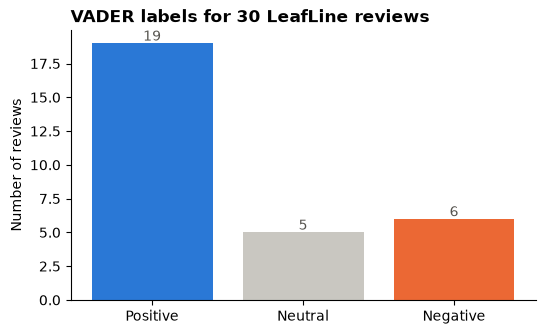

In [13]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(counts.index, counts.values, color=[BLUE, GREY, ORANGE])
for i, value in enumerate(counts.values):
    ax.text(i, value + 0.2, str(value), ha="center", color=INK)
ax.set_title("VADER labels for 30 LeafLine reviews")
ax.set_ylabel("Number of reviews")
plt.show()

> **Check your understanding**
>
> 1. A review has a compound score of 0.03. What label does it get, and why might the analyst still want to read it?
> 2. Why do we run VADER on the original text instead of the cleaned, stopword-free words?

---

## Part 7: Checking the scores against star ratings

A model's output is a claim, not a fact. Here we are lucky: every review also has a **star rating** chosen by the customer. If VADER works well, low-star reviews should have low compound scores.

> **Predict, then reveal**
>
> Review 8 reads *"Great, another 40 minute wait for a lukewarm drink."* and has **1 star**. Will VADER call it positive, neutral or negative?

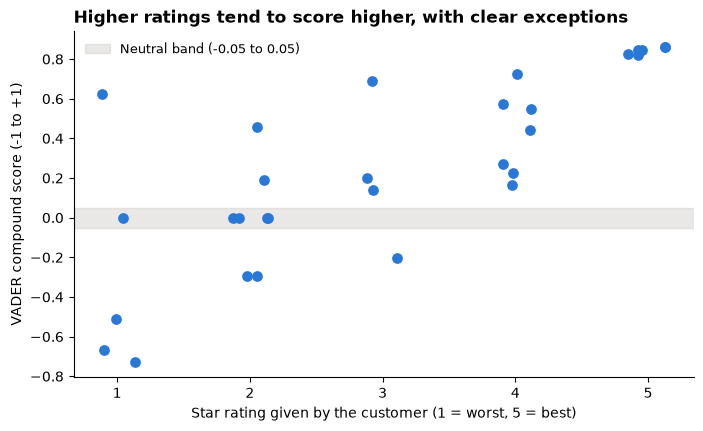

Average compound score by star rating:
       count   mean
stars              
1          5 -0.256
2          8  0.008
3          4  0.207
4          7  0.422
5          6  0.844

Correlation between stars and compound score: r = 0.79


In [14]:
rng = np.random.default_rng(12)   # fixed seed: the small sideways jitter is the same every run
jitter = rng.uniform(-0.15, 0.15, len(reviews))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.axhspan(-0.05, 0.05, color=GREY, alpha=0.4, label="Neutral band (-0.05 to 0.05)")
ax.scatter(reviews["stars"] + jitter, reviews["compound"], s=45, color=BLUE)
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xlabel("Star rating given by the customer (1 = worst, 5 = best)")
ax.set_ylabel("VADER compound score (-1 to +1)")
ax.set_title("Higher ratings tend to score higher, with clear exceptions")
ax.legend(frameon=False, loc="upper left", fontsize=9)
plt.show()

print("Average compound score by star rating:")
print(reviews.groupby("stars")["compound"].agg(["count", "mean"]).round(3).to_string())
print(f"\nCorrelation between stars and compound score: r = {reviews['stars'].corr(reviews['compound']):.2f}")

The chart above shows a clear upward pattern, but some unhappy customers (1 or 2 stars) sit in or above the neutral band. List them:

In [15]:
unhappy_not_negative = reviews[(reviews["stars"] <= 2) & (reviews["sentiment"] != "Negative")]
print("Reviews with 1-2 stars that VADER does NOT label Negative:", len(unhappy_not_negative))
unhappy_not_negative[["stars", "compound", "sentiment", "text"]]

Reviews with 1-2 stars that VADER does NOT label Negative: 8


,stars,compound,sentiment,text
review_id,,,,
2,2,0.0000,Neutral,Waited 35 minutes for one drink. The queue was huge and nobody explained the delay.
7,2,0.4588,Positive,"Too sweet even at 30% sugar, and the ice melted before I got back to the office."
8,1,0.6249,Positive,"Great, another 40 minute wait for a lukewarm drink."
10,2,0.1901,Positive,The app showed my order as ready but the staff could not find it. I waited another 20 ...
23,2,0.0000,Neutral,"Convenient location, but the wait times are unpredictable."
25,2,0.0000,Neutral,"The app kept logging me out, and the queue was very long."
27,1,0.0000,Neutral,Overpriced and watery. Never again.
30,2,0.0000,Neutral,Waited 30 minutes at the counter while app orders kept jumping the queue.


Read each review in the table above and ask why the lexicon missed it. The reasons fall into a few groups:

| Blind spot | Example from the table | What to do |
|---|---|---|
| **Domain words** missing from the lexicon | *wait*, *queue*, *minutes*, *watery*, *lukewarm* | Add domain words with ratings, or use a keyword list for known problems |
| **Sarcasm** | "Great, another 40 minute wait…" | Read a sample; no word-based method handles sarcasm reliably |
| **Facts that imply a feeling** | "I missed my train because the order took 25 minutes" | Combine sentiment with topic keywords |
| **Mixed reviews** | Praise and complaint in one review | Score sentences separately, or by aspect |
| **Other languages** | Chinese reviews | VADER is English only; Chinese text needs its own tokenizer (Chinese has no spaces between words) and its own lexicon |

> **Remember**
>
> Sentiment scores are useful for **large volumes** and **trends** (is this month worse than last month?). They are weak evidence about any **single** review. Always validate against a second source, such as star ratings or a sample read by a person.

---

## Part 8: From reviews to a decision

The manager's question was **what should we fix first?** Topics alone and sentiment alone each fall short, so we combine them. We define a few **aspects** by keyword lists, flag every review that mentions each aspect, and summarise the reviews in each group. Because VADER misses complaints about waiting, we lead with the **star rating** and show the compound score next to it.

In [16]:
ASPECTS = {
    "waiting": {"wait", "waited", "queue", "slow", "minutes", "minute", "long", "delay"},
    "app": {"app"},
    "taste": {"taste", "tasty", "delicious", "sweet", "watery", "pearls", "fresh", "lukewarm"},
    "staff": {"staff", "cashier", "rude", "friendly", "polite", "kind", "nobody"},
    "price": {"price", "cheap", "expensive", "overpriced", "discount", "paid", "charged"},
}

for aspect, keywords in ASPECTS.items():
    reviews[aspect] = reviews["words"].apply(lambda words: bool(keywords & set(words)))

rows = []
for aspect in ASPECTS:
    group = reviews[reviews[aspect]]
    rows.append({
        "aspect": aspect,
        "reviews": len(group),
        "% of all reviews": 100 * len(group) / len(reviews),
        "average stars": group["stars"].mean(),
        "% with 1-2 stars": 100 * (group["stars"] <= 2).mean(),
        "average compound": group["compound"].mean(),
    })
aspects = pd.DataFrame(rows).set_index("aspect").sort_values("% with 1-2 stars", ascending=False)
aspects.round(2)

,reviews,% of all reviews,average stars,% with 1-2 stars,average compound
aspect,,,,,
waiting,12,40.00,2.58,66.67,0.17
app,9,30.00,2.78,55.56,0.06
staff,9,30.00,3.11,44.44,0.20
price,7,23.33,3.29,28.57,0.28
taste,11,36.67,3.36,27.27,0.45


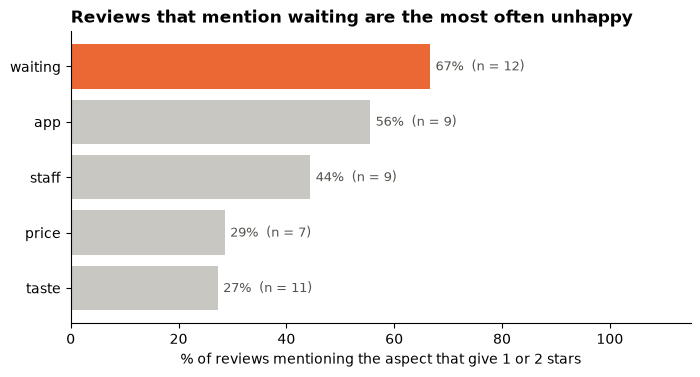

In [17]:
low_share = aspects["% with 1-2 stars"].sort_values()
worst = low_share.index[-1]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(low_share.index, low_share.values, color=[ORANGE if a == worst else GREY for a in low_share.index])
for i, (aspect, value) in enumerate(low_share.items()):
    ax.text(value + 1, i, f"{value:.0f}%  (n = {aspects.loc[aspect, 'reviews']})", va="center", fontsize=9, color=INK)
ax.set_xlim(0, 115)
ax.set_title(f"Reviews that mention {worst} are the most often unhappy")
ax.set_xlabel("% of reviews mentioning the aspect that give 1 or 2 stars")
plt.show()

A review can mention several aspects, so the groups overlap and their counts add up to more than 30. The `n` beside each bar is the number of reviews behind the percentage: with 30 reviews, every group is small.

Where does the worst aspect happen? Break it down by branch:

In [18]:
by_branch = reviews.groupby("branch").agg(
    reviews=("stars", "size"),
    mention_worst=(worst, "sum"),
    average_stars=("stars", "mean"),
)
by_branch[f"% mentioning {worst}"] = 100 * by_branch["mention_worst"] / by_branch["reviews"]
by_branch.round(2)

,reviews,mention_worst,average_stars,% mentioning waiting
branch,,,,
Campus,10,1,3.6,10.0
Riverside,10,4,2.9,40.0
Station,10,7,2.6,70.0


### Writing the recommendation

A recommendation from text mining has four parts. Fill them in from the outputs above:

| Part | Content |
|---|---|
| **Finding** | Which aspect is most often linked to unhappy customers, and in which branches |
| **Evidence** | The share of 1–2 star reviews for that aspect, with *n*; two or three quoted reviews |
| **Recommendation** | A specific action the manager controls, for example a separate pick-up counter for app orders and a visible waiting-time display |
| **Caveats** | Synthetic data; only 30 reviews; keyword lists miss synonyms; VADER under-scores waiting complaints; a review is one visit, not one customer |

> **Association is not causation**
>
> Reviews that mention waiting are more often unhappy. That supports fixing waiting times, but it does not prove that shorter waits will raise ratings. A careful manager tests the change in one branch first and compares ratings before and after.

> **Ethics and privacy**
>
> Real reviews and chat logs can contain names, phone numbers and order numbers. Remove personal details before analysis, store text securely, and report patterns, never individual customers.

> **Check your understanding**
>
> The app aspect also has many low ratings. Read the app reviews (filter `reviews[reviews["app"]]`). Is the problem the same in every review? What would you recommend to the app team?

---

## Summary

| Idea | One-line takeaway |
|---|---|
| Unstructured text | Most business feedback is text; text mining turns it into counts, scores and categories |
| Tokenising | Lowercase, split with `word_tokenize`, keep `isalpha()` tokens for counting |
| Stopwords | Remove standard and domain stopwords for topics; never for sentiment ("not") |
| Word frequency | Says what people talk about, not what they feel; show it as a sorted bar chart |
| Word cloud | A first impression only: area is read poorly; pairs (bigrams) add context |
| VADER | Lexicon plus rules gives a compound score from −1 to +1; ±0.05 thresholds |
| Validation | Compare with star ratings or a read sample; watch for domain words, sarcasm, mixed reviews, other languages |
| Decision | Combine aspects and ratings; finding, evidence, recommendation, caveats |

## Quick reference

| You want to… | Code |
|---|---|
| Use the bundled NLTK data | Run the NLTK setup cell at the top of this notebook |
| Tokenise | `word_tokenize(text.lower())` |
| Keep words only | `[t for t in tokens if t.isalpha()]` |
| Stopword list | `set(stopwords.words("english"))`, then `.update([...])` or `\|` for your own |
| Count words | `nltk.FreqDist(words).most_common(10)` |
| Word cloud | `WordCloud(width=800, height=400, background_color="white", random_state=3).generate_from_frequencies(freq)` |
| Word pairs | `Counter(nltk.bigrams(words))` |
| Sentiment | `SentimentIntensityAnalyzer().polarity_scores(text)["compound"]` |

---

## Closing quiz

Answer in your own words, alone, in about two minutes per question.

1. Give two examples of unstructured data a bank holds, and one business question each could answer.
2. What does `word_tokenize("Not bad!")` return, and which tokens survive `isalpha()`?
3. Why is "the" removed before counting words, but "not" kept before scoring sentiment?
4. A word cloud of hotel reviews shows "room" as the biggest word. What can you conclude, and what can you not?
5. VADER gives "The delivery was slow" a compound score of 0.0. Explain why, using the word "lexicon".
6. What does a compound score of −0.62 mean, and what label does it get?
7. Name two ways to check whether sentiment scores are trustworthy for your data.
8. Write one recommendation sentence for LeafLine that includes a finding, a number from the outputs and a caveat.

---

## This afternoon

**Lab:** [Applied Lab 3: Text mining application](D3_lab_lab3_text_mining.md) (graded, 3%). You apply the same routine to customer reviews of a tablet computer: tokenise, remove stopwords, find the key terms, score sentiment with VADER and recommend a product change.

The forecasting lecture, [Day 3 lecture: Forecasting](D3_lecture_forecasting.md), prepares you for [Applied Lab 4](D3_lab_lab4_forecasting.md).